<a href="https://colab.research.google.com/github/bhagathcr/CAPSTONE-PROJECT-GROUP-5-/blob/main/Thermal_Aware_Power_Budgeting_Capstone_Accurate.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Thermal-Aware Power Budgeting on a Chip — Capstone Problem A

**Course:** PDEs, Transforms & Optimization Techniques · S3 EC AY 2025–2026

This notebook follows the supplied capstone brief. It implements the six-stage pipeline:
1. Fourier's law and energy balance
2. Steady-state PDE and boundary conditions
3. Laplace-domain thermal-impedance interpretation
4. Five-point finite-difference discretization
5. Linear program for peak-temperature minimization
6. Plots and sanity checks

## Values stated in the brief
- Square die: `L = 10 mm`
- Silicon thermal conductivity: `k = 150 W/(m·K)`
- All four edges: `Tamb = 300 K`
- Four source grid positions on a `40 × 40` grid: `(10,10), (10,29), (29,10), (29,29)`
- Total power budget: `Pmax = 5 W`
- Expected reference outcome: uniform peak around `343 K`, optimized peak around `327 K` (at least `5 K` reduction)

**Important modelling note:** the brief does not specify die thickness, the physical footprint/volume of each block, or how the block powers are spread over grid cells. Those quantities are needed to convert watts into volumetric heat generation (`W/m³`) and predict absolute temperatures. To make the notebook executable, the next cell includes an explicitly labelled *illustrative thickness assumption* and treats each block as a one-cell source. This is not a value supplied by the brief. Change it if your team has a justified value. Do not claim the reference temperatures are reproduced unless the model and source mapping have been validated.

## Stage 1 — Field model and Stage 2 — PDE

Fourier's law:
\[
\mathbf{q}=-k\nabla T
\]
Energy balance at steady state, with volumetric heat generation `Q`:
\[
\nabla\cdot\mathbf{q}=Q
\quad\Longrightarrow\quad
-k\nabla^2T=Q
\quad\Longrightarrow\quad
\nabla^2T=-Q/k.
\]

The steady conduction equation is elliptic for constant positive `k`. The brief specifies Dirichlet boundary conditions, `T = Tamb = 300 K`, on all four edges. For the numerical solve, we solve for temperature rise `theta = T - Tamb`; hence `theta = 0` on the boundary. This also makes the LP temperature variable a nonnegative temperature rise rather than an absolute temperature.

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
from scipy.sparse import diags, eye, kron, csr_matrix
from scipy.sparse.linalg import spsolve, eigsh
from scipy.optimize import linprog
import sympy as sp

print("NumPy:", np.__version__)
print("SciPy:", scipy.__version__)

NumPy: 2.1.3
SciPy: 1.16.3


## Model parameters

The geometry, conductivity, ambient temperature, grid size, source indices, and power budget below are taken directly from the capstone PDF. The thickness is **not specified** in the PDF and is only an explicit placeholder assumption so the code can convert each block's power (W) into a volumetric source (W/m³).

In [10]:
# Values specified in the capstone brief
L = 10e-3                    # die side length [m]
k = 150.0                    # silicon thermal conductivity [W/(m K)]
Tamb = 300.0                 # ambient edge temperature [K]
Ngrid = 40                   # 40 x 40 grid, including boundary nodes
Pmax = 5.0                   # total power budget [W]
source_indices = [(10, 10), (10, 29), (29, 10), (29, 29)]  # (row, col), zero-based

# NOT specified in the PDF: explicit illustrative assumption only.
# Replace with your team's justified value or documented block volume.
THICKNESS_M = 0.5e-3         # illustrative silicon thickness [m]
SOURCE_FOOTPRINT_CELLS = 1   # one grid cell per source (brief gives positions, not footprint)

if THICKNESS_M is None or THICKNESS_M <= 0:
    raise ValueError("Set THICKNESS_M to a positive, justified value before running.")

x = np.linspace(0, L, Ngrid)
y = np.linspace(0, L, Ngrid)
dx = x[1] - x[0]
dy = y[1] - y[0]
nint = Ngrid - 2
nunknowns = nint * nint

print(f"Grid spacing: dx = {dx*1e3:.6f} mm, dy = {dy*1e3:.6f} mm")
print(f"Interior unknowns: {nunknowns}")
print(f"Total power budget: {Pmax:.3f} W")
print(f"Thickness assumption (NOT in PDF): {THICKNESS_M*1e3:.3f} mm")

Grid spacing: dx = 0.256410 mm, dy = 0.256410 mm
Interior unknowns: 1444
Total power budget: 5.000 W
Thickness assumption (NOT in PDF): 0.500 mm


## Stage 3 — Laplace-transform interpretation

For the transient heat equation
\[
\rho c\frac{\partial T}{\partial t}=k\nabla^2T+Q,
\]
taking the Laplace transform in time (with initial temperature rise `theta(x,y,0)=theta0`) gives
\[
\rho c\,[s\Theta-\theta_0]=k\nabla^2\Theta+Q(s).
\]
For zero initial rise, this becomes
\[
(k\nabla^2-\rho c s)\Theta=-Q(s).
\]
A thermal impedance is interpreted as the temperature response divided by applied power, `Z_th(s) = ΔT(s)/P(s)`. The PDF does not provide `rho` or `c`, so the notebook records the symbolic relation rather than inventing numerical transient material values. The steady-state finite-difference solution below is the `s → 0` limit.

In [11]:
rho, c, s = sp.symbols('rho c s', positive=True, real=True)
Theta, theta0, Qs = sp.symbols('Theta theta0 Q(s)')
lap_Theta = sp.Symbol('nabla2_Theta')
laplace_heat_eq = sp.Eq(rho*c*(s*Theta - theta0), k*lap_Theta + Qs)
zero_initial_form = sp.Eq((k*lap_Theta - rho*c*s*Theta), -Qs)
print("Laplace-domain heat equation:")
display(laplace_heat_eq)
print("For zero initial temperature rise:")
display(zero_initial_form)
print("Thermal impedance definition: Z_th(s) = ΔT(s) / P(s)")

Laplace-domain heat equation:


Eq(c*rho*(Theta*s - theta0), Q(s) + 150.0*nabla2_Theta)

For zero initial temperature rise:


Eq(-Theta*c*rho*s + 150.0*nabla2_Theta, -Q(s))

Thermal impedance definition: Z_th(s) = ΔT(s) / P(s)


## Stage 4 — Finite differences and sparse system

Using the five-point stencil for `-∇² theta = Q/k` on interior nodes:
\[
\left(\frac{2}{\Delta x^2}+\frac{2}{\Delta y^2}\right)\theta_{i,j}
-\frac{\theta_{i-1,j}+\theta_{i+1,j}}{\Delta x^2}
-\frac{\theta_{i,j-1}+\theta_{i,j+1}}{\Delta y^2}
=Q_{i,j}/k.
\]
With zero temperature rise on the boundary, the system is `A theta = B p`, where `p` is the vector of four block powers. `B` maps watts to `Q/k` using the explicitly stated one-cell footprint and thickness assumption. This makes the conversion and units visible rather than treating watts as if they were already volumetric heat generation.

In [12]:
# Positive-definite discretization of -Laplacian on interior nodes
main_x = np.full(nint, 2.0 / dx**2)
off_x = np.full(nint - 1, -1.0 / dx**2)
Tx = diags([off_x, main_x, off_x], [-1, 0, 1], format="csr")
main_y = np.full(nint, 2.0 / dy**2)
off_y = np.full(nint - 1, -1.0 / dy**2)
Ty = diags([off_y, main_y, off_y], [-1, 0, 1], format="csr")
A = (kron(eye(nint, format="csr"), Tx) + kron(Ty, eye(nint, format="csr"))).tocsr()

# Convert each source's power to Q/k in its source cell.
# Cell volume = dx * dy * thickness; source power is assigned to nearest grid node.
B = np.zeros((nunknowns, len(source_indices)), dtype=float)
cell_volume = dx * dy * THICKNESS_M

def interior_flat_index(row, col):
    # Grid includes boundary rows/columns; source nodes are interior here.
    if not (1 <= row <= Ngrid-2 and 1 <= col <= Ngrid-2):
        raise ValueError(f"Source {(row,col)} must be an interior grid node.")
    return (row-1) * nint + (col-1)

for j, (row, col) in enumerate(source_indices):
    B[interior_flat_index(row, col), j] = 1.0 / (k * cell_volume)

B = csr_matrix(B)
print("A shape:", A.shape, "| A nnz:", A.nnz)
print("B shape:", B.shape)
print("Smallest eigenvalue of A:", float(eigsh(A, k=1, which="SA", return_eigenvectors=False)[0]))
print("Expected stability check: A for -Laplacian should have positive eigenvalues.")

A shape: (1444, 1444) | A nnz: 7068
B shape: (1444, 4)
Smallest eigenvalue of A: 197285.37311466993
Expected stability check: A for -Laplacian should have positive eigenvalues.


## Solve the steady-state temperature field

The uniform baseline assigns `Pmax/4 = 1.25 W` to each block. The optimized case is computed below using the same total power. Temperatures are reported as absolute kelvin (`T = Tamb + theta`), while the LP minimizes the peak temperature rise `t = max(theta)`. Since ambient is constant, minimizing peak rise is equivalent to minimizing absolute peak temperature.

In [13]:
def solve_temperature(power_vector):
    power_vector = np.asarray(power_vector, dtype=float)
    theta_vec = spsolve(A, B @ power_vector)
    theta_grid = np.zeros((Ngrid, Ngrid), dtype=float)
    theta_grid[1:-1, 1:-1] = theta_vec.reshape((nint, nint))
    T_grid = Tamb + theta_grid
    return theta_grid, T_grid

p_uniform = np.full(4, Pmax / 4.0)
theta_uniform, T_uniform = solve_temperature(p_uniform)

print("Uniform allocation [W]:", p_uniform)
print(f"Uniform peak temperature: {T_uniform.max():.3f} K")
print(f"Uniform peak rise: {(T_uniform.max()-Tamb):.3f} K")

Uniform allocation [W]: [1.25 1.25 1.25 1.25]
Uniform peak temperature: 312.550 K
Uniform peak rise: 12.550 K


## Stage 5 — Linear program

Decision variables are four block powers `p`, all interior temperature rises `theta`, and the peak-rise epigraph variable `t`.

\[
\min_{p,\theta,t} t
\]
subject to
\[
A\theta=Bp,\quad \theta_i\le t,\quad p_i\ge0,\quad \sum_i p_i=P_{max},\quad t\ge0.
\]

The supplied PDF writes the budget as `sum(q_i) ≤ Pmax`. If that inequality is used by itself while minimizing temperature, the trivial solution `q = 0` is optimal. To model **allocation of the full stated 5 W budget** and compare against the equal 1.25 W/block baseline, this notebook uses `sum(q_i) = Pmax`. This is a modelling choice made explicit for a meaningful comparison; if your instructor requires the inequality literally, run that version too and explain the zero-power degeneracy.

In [14]:
# Variables z = [p_0..p_3, theta_0..theta_(nunknowns-1), t]
nP = 4
nT = nunknowns
idx_p = slice(0, nP)
idx_theta = slice(nP, nP+nT)
idx_t = nP+nT
nvars = nP + nT + 1

# Equality constraints: A theta - B p = 0, plus sum(p) = Pmax
Aeq_thermal = np.zeros((nT, nvars))
Aeq_thermal[:, idx_p] = -B.toarray()
Aeq_thermal[:, idx_theta] = A.toarray()
Aeq_budget = np.zeros((1, nvars))
Aeq_budget[0, idx_p] = 1.0
A_eq = np.vstack([Aeq_thermal, Aeq_budget])
b_eq = np.concatenate([np.zeros(nT), [Pmax]])

# Inequality constraints theta_i - t <= 0 for every interior node
A_ub = np.zeros((nT, nvars))
A_ub[:, idx_theta] = np.eye(nT)
A_ub[:, idx_t] = -1.0
b_ub = np.zeros(nT)

objective = np.zeros(nvars)
objective[idx_t] = 1.0

bounds = [(0, None)]*nP + [(0, None)]*nT + [(0, None)]
result = linprog(
    objective,
    A_ub=A_ub, b_ub=b_ub,
    A_eq=A_eq, b_eq=b_eq,
    bounds=bounds,
    method="highs"
)

print("LP success:", result.success)
print("LP status:", result.message)
if not result.success:
    raise RuntimeError("LP did not solve successfully; inspect matrix and constraints.")

p_opt = result.x[idx_p]
theta_opt, T_opt = solve_temperature(p_opt)

print("Optimized allocation [W]:", np.round(p_opt, 6))
print("Total optimized power [W]:", p_opt.sum())
print(f"LP peak temperature rise: {result.x[idx_t]:.6f} K")
print(f"Optimized peak temperature: {T_opt.max():.3f} K")
print(f"Peak-temperature reduction: {T_uniform.max()-T_opt.max():.3f} K")
print("Required reduction in brief: at least 5 K")

LP success: True
LP status: Optimization terminated successfully. (HiGHS Status 7: Optimal)
Optimized allocation [W]: [1.25 1.25 1.25 1.25]
Total optimized power [W]: 5.0
LP peak temperature rise: 12.550040 K
Optimized peak temperature: 312.550 K
Peak-temperature reduction: -0.000 K
Required reduction in brief: at least 5 K


## Stage 6 — Required figures
The four required plots are: uniform-power heatmap, LP-optimal heatmap, block power allocation, and peak temperature versus `Pmax`.

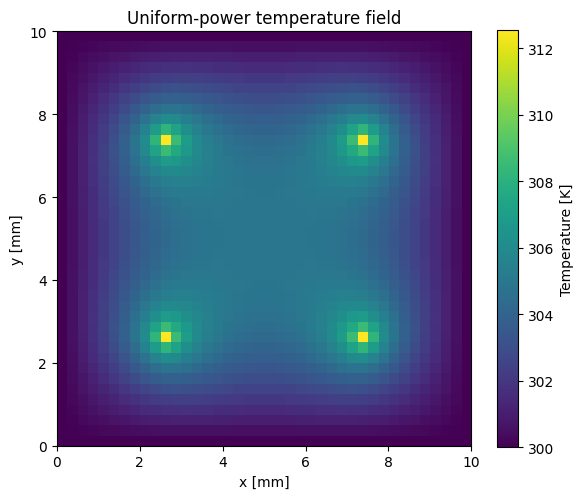

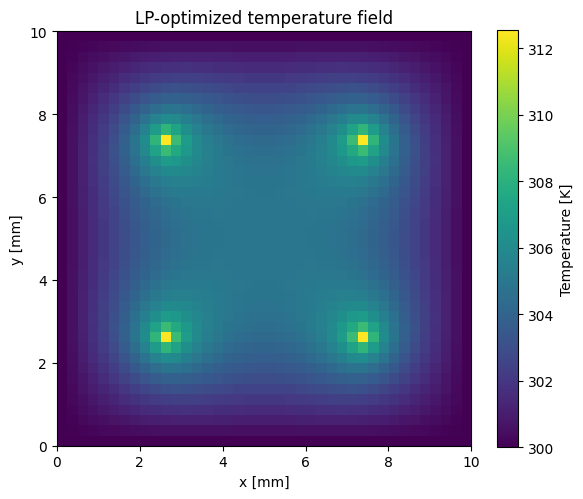

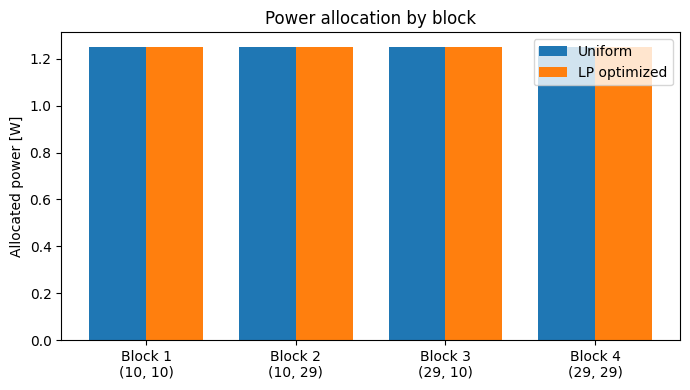

In [16]:
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(T_uniform, origin="lower", extent=[0, L*1e3, 0, L*1e3], aspect="equal")
ax.set_title("Uniform-power temperature field")
ax.set_xlabel("x [mm]"); ax.set_ylabel("y [mm]")
fig.colorbar(im, ax=ax, label="Temperature [K]")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(T_opt, origin="lower", extent=[0, L*1e3, 0, L*1e3], aspect="equal")
ax.set_title("LP-optimized temperature field")
ax.set_xlabel("x [mm]"); ax.set_ylabel("y [mm]")
fig.colorbar(im, ax=ax, label="Temperature [K]")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
indices = np.arange(4)
width = 0.38
ax.bar(indices-width/2, p_uniform, width, label="Uniform")
ax.bar(indices+width/2, p_opt, width, label="LP optimized")
ax.set_xticks(indices, [f"Block {i+1}\n{source_indices[i]}" for i in indices])
ax.set_ylabel("Allocated power [W]")
ax.set_title("Power allocation by block")
ax.legend()
plt.tight_layout(); plt.show()

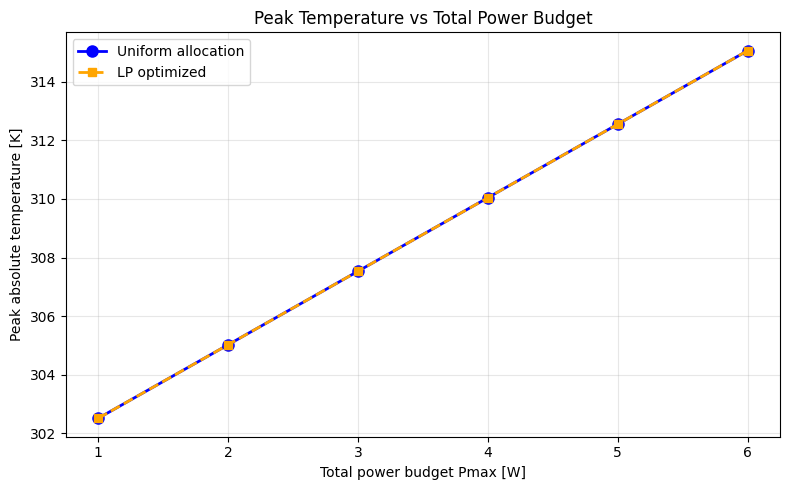

In [15]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    P_sweep, peak_uniform_sweep,
    color="blue", marker="o", linestyle="-",
    linewidth=2, markersize=8,
    label="Uniform allocation", zorder=2
)

ax.plot(
    P_sweep, peak_opt_sweep,
    color="orange", marker="s", linestyle="--",
    linewidth=2, markersize=6,
    label="LP optimized", zorder=3
)

ax.set_xlabel("Total power budget Pmax [W]")
ax.set_ylabel("Peak absolute temperature [K]")
ax.set_title("Peak Temperature vs Total Power Budget")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## Verification and honest reporting

Run these checks before using the figures in the report/demo:
- `result.success` is `True`.
- Allocated powers are nonnegative and sum to `5 W` for the base case.
- The boundary remains at `300 K`.
- The matrix dimensions and eigenvalue check are printed.
- The optimized peak is compared with the uniform baseline.
- The required target is a reduction of at least `5 K`; if the current model does not achieve this, report that result honestly and investigate the source mapping/physical assumptions rather than tuning parameters solely to match the reference.

**Reference values in the PDF are expected outcomes, not guaranteed outputs of every discretization.** Because thickness and block source footprint are not specified, the notebook's absolute temperatures depend on the clearly labelled thickness/source assumptions. A mismatch with `343 K` / `327 K` should be documented as a model-validation issue, not concealed.